In [3]:
import pandas as pd
import glob
import numpy as np
from sklearn.metrics import roc_auc_score
from sklearn.model_selection import train_test_split
from sklearn.metrics import classification_report, confusion_matrix
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import RobustScaler
from xgboost import XGBClassifier
from sklearn.model_selection import RandomizedSearchCV, TimeSeriesSplit
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.metrics import (
    PrecisionRecallDisplay,
    RocCurveDisplay,
    confusion_matrix,
)
from onnxmltools.convert.xgboost.operator_converters.XGBoost import (
    convert_xgboost,
)
from skl2onnx import convert_sklearn, update_registered_converter
from skl2onnx.common.data_types import FloatTensorType
from skl2onnx.common.shape_calculator import (
    calculate_linear_classifier_output_shapes,
)
import folium
from folium.plugins import MarkerCluster
import onnxruntime as rt

### 1. Load semua datasets

In [4]:
pothole_datasets = glob.glob("./data/Pothole/*.csv")
road_datasets = glob.glob("./data/RoadCondition/*.csv")
dfs = []
for file in pothole_datasets:
    df_temp = pd.read_csv(file)
    df_temp["label"] = 1   # 1 → pothole
    dfs.append(df_temp)

for file in road_datasets:
    df_temp = pd.read_csv(file)
    df_temp["label"] = 0   # 0 → smooth road
    dfs.append(df_temp)

df_raw = pd.concat(dfs, ignore_index=True)
df = pd.DataFrame(df_raw)
print("Combined dataset shape:", df.shape)

Combined dataset shape: (21284, 11)


### 2. Clean Data

**(IMPORTANT) Sebelum menggunakan `TimeSeriesSplit()` bagusnya diurutkan berdasarkan timestamp**

In [5]:
df_clean = df.sort_values(by="timestamp").reset_index(drop=True)

**Hilangkan bagian yang null**

In [6]:
df_clean = df.dropna(subset=["latitude", "longitude", "speed", "accelerometerX"])

In [7]:
print("Ukuran setelah pembersihan missing values:", df_clean.shape[0])
print("Jumlah missing values:", df.shape[0] - df_clean.shape[0])

Ukuran setelah pembersihan missing values: 21188
Jumlah missing values: 96


### Menambahkan beberapa fitur

Karena magnitude dan gyro masih berbentuk vector, maka perlu diubah ke bentuk skalar dengan rumus:

$\text{Magnitude} = \sqrt{x^2 + y^2 + z^2}$

In [8]:
df_clean["acc_magnitude"] = np.sqrt(
    df_clean["accelerometerX"] ** 2
    + df_clean["accelerometerY"] ** 2
    + df_clean["accelerometerZ"] ** 2
)

df_clean["gyro_magnitude"] = np.sqrt(
    df_clean["gyroX"] ** 2
    + df_clean["gyroY"] ** 2
    + df_clean["gyroZ"] ** 2
)

df_clean["jerk"] = df_clean["acc_magnitude"].diff().abs()
df_clean["angular_jerk"] = df_clean["gyro_magnitude"].diff().abs()
df_clean["speed_diff"] = df_clean["speed"].diff()

### Convert ke jendela waktu

In [9]:
window_size = 10
target_cols = [
    "acc_magnitude",
    "gyro_magnitude",
    "jerk",
    "speed",
    "accelerometerZ",
]

In [10]:
for col in target_cols:
    df_clean[f"{col}_std"] = (
        df_clean[col]
        .rolling(window=window_size, min_periods=window_size)
        .std()
    )
    df_clean[f"{col}_max"] = (
        df_clean[col]
        .rolling(window=window_size, min_periods=window_size)
        .max()
    )
    df_clean[f"{col}_min"] = (
        df_clean[col]
        .rolling(window=window_size, min_periods=window_size)
        .min()
    )
    df_clean[f"{col}_range"] = df_clean[f"{col}_max"] - df_clean[f"{col}_min"]

df_clean = df_clean.dropna().reset_index(drop=True)
metadata_cols = ["timestamp", "latitude", "longitude"]
metadata = df_clean[metadata_cols].copy()
y = df_clean["label"].copy()
X = df_clean.drop(columns=metadata_cols + ["label"])

In [11]:
print("=== PIPELINE DATA CLEANING SELESAI ===")
print(f"X (Matriks Fitur Latih) : {X.shape}")
print(f"y (Target Label)        : {y.shape}")
print(f"Metadata GPS           : {metadata.shape}\n")

print("Daftar Fitur yang dilatih ke Model Machine Learning:")
print(X.columns.tolist())

=== PIPELINE DATA CLEANING SELESAI ===
X (Matriks Fitur Latih) : (21178, 32)
y (Target Label)        : (21178,)
Metadata GPS           : (21178, 3)

Daftar Fitur yang dilatih ke Model Machine Learning:
['speed', 'accelerometerX', 'accelerometerY', 'accelerometerZ', 'gyroX', 'gyroY', 'gyroZ', 'acc_magnitude', 'gyro_magnitude', 'jerk', 'angular_jerk', 'speed_diff', 'acc_magnitude_std', 'acc_magnitude_max', 'acc_magnitude_min', 'acc_magnitude_range', 'gyro_magnitude_std', 'gyro_magnitude_max', 'gyro_magnitude_min', 'gyro_magnitude_range', 'jerk_std', 'jerk_max', 'jerk_min', 'jerk_range', 'speed_std', 'speed_max', 'speed_min', 'speed_range', 'accelerometerZ_std', 'accelerometerZ_max', 'accelerometerZ_min', 'accelerometerZ_range']


### Split data
komposisi data:
1. test size = 20%
2. random state = 42

In [12]:
test_size = 0.2
random_state = 42

In [13]:
X_train, X_test, y_train, y_test, meta_train, meta_test = train_test_split(
    X,
    y,
    metadata,
    test_size=test_size,
    random_state=random_state,
    stratify=y,
)

In [14]:
print(f"Jumlah Data Train : {X_train.shape[0]} baris")
print(f"Jumlah Data Test  : {X_test.shape[0]} baris")
ratio_imbalance = (y_train == 0).sum() / (y_train == 1).sum()
print(
    f"Rasio Imbalance Class (scale_pos_weight untuk XGBoost): {ratio_imbalance:.2f}"
)

Jumlah Data Train : 16942 baris
Jumlah Data Test  : 4236 baris
Rasio Imbalance Class (scale_pos_weight untuk XGBoost): 1.15


### Skalarisasi
Proses ini menggunakan `RobustScaler` yang cocok untuk mengatasi outlier, pada proses ini digunakan `XGBClassifier` untuk menangani data tidak seimbang (misalnya jumlah sampel jalan yg berlubang jauh lebih sedikit dibanding jalan mulus).

In [15]:
pipeline = Pipeline(
    [
        ("scaler", RobustScaler()),  # Scaler dimasukkan ke dalam Pipeline
        (
            "xgb",
            XGBClassifier(
                random_state=42,
                eval_metric="logloss",
                scale_pos_weight=ratio_imbalance,  # Penanganan Imbalanced Data
            ),
        ),
    ]
)

### Hyperparameter Tuning

- n_estimators: Jumlah pohon keputusan yang dibangun (100, 200, atau 300).
- max_depth: Kedalaman maksimum setiap pohon (makin tinggi makin kompleks, namun rentan overfitting).
- learning_rate: Bobot kontribusi setiap pohon baru terhadap hasil akhir (step size).
- subsample: Persentase baris data yang diambil secara acak untuk membangun tiap pohon.
- colsample_bytree: Persentase kolom/fitur yang diambil secara acak untuk membangun tiap pohon.
- gamma: Batas minimum pengurangan loss yang dibutuhkan untuk membelah (split) cabang pohon.

In [16]:
param_distributions = {
    "xgb__n_estimators": [100, 200, 300],
    "xgb__max_depth": [3, 5, 7, 9],
    "xgb__learning_rate": [0.01, 0.05, 0.1, 0.2],
    "xgb__subsample": [0.6, 0.8, 1.0],
    "xgb__colsample_bytree": [0.6, 0.8, 1.0],
    "xgb__gamma": [0, 0.1, 0.3],
}

* **Iterasi 1:** Train [Bagian 1] $\rightarrow$ Test [Bagian 2]
* **Iterasi 2:** Train [Bagian 1 + 2] $\rightarrow$ Test [Bagian 3]
* **Iterasi 3:** Train [Bagian 1 + 2 + 3] $\rightarrow$ Test [Bagian 4]
* **Iterasi 4:** Train [Bagian 1 + 2 + 3 + 4] $\rightarrow$ Test [Bagian 5]
* **Iterasi 5:** Train [Bagian 1 + 2 + 3 + 4 + 5] $\rightarrow$ Test [Bagian 6]

Selalu menggunakan data masa lalu (past) sebagai data training, dan data masa depan (future) sebagai data validasi/pengujian (walk-forward validation).

Kegunaan uttama adalah mencegah model melihat data masa depan untuk memprediksi data masa lalu

In [17]:
cv_strategy = TimeSeriesSplit(n_splits=5)

In [18]:
search = RandomizedSearchCV(
    estimator=pipeline,
    param_distributions=param_distributions,
    n_iter=30,  # Jumlah kombinasi sampel acak
    scoring="f1",  # Optimalkan F1-Score (penting untuk kelas Pothole)
    cv=cv_strategy,
    random_state=42,
    n_jobs=-1,
    verbose=2,
)

In [19]:
print("Memulai Hyperparameter Tuning...")
search.fit(X_train, y_train)
best_model = search.best_estimator_

Memulai Hyperparameter Tuning...
Fitting 5 folds for each of 30 candidates, totalling 150 fits
[CV] END xgb__colsample_bytree=0.6, xgb__gamma=0.3, xgb__learning_rate=0.05, xgb__max_depth=7, xgb__n_estimators=200, xgb__subsample=0.8; total time=   9.4s
[CV] END xgb__colsample_bytree=0.6, xgb__gamma=0.3, xgb__learning_rate=0.05, xgb__max_depth=7, xgb__n_estimators=200, xgb__subsample=0.8; total time=  11.9s
[CV] END xgb__colsample_bytree=0.6, xgb__gamma=0.3, xgb__learning_rate=0.05, xgb__max_depth=7, xgb__n_estimators=200, xgb__subsample=0.8; total time=  13.5s
[CV] END xgb__colsample_bytree=0.8, xgb__gamma=0.1, xgb__learning_rate=0.01, xgb__max_depth=7, xgb__n_estimators=200, xgb__subsample=0.8; total time=  15.5s
[CV] END xgb__colsample_bytree=0.8, xgb__gamma=0.1, xgb__learning_rate=0.01, xgb__max_depth=7, xgb__n_estimators=200, xgb__subsample=0.8; total time=  19.3s
[CV] END xgb__colsample_bytree=0.8, xgb__gamma=0.1, xgb__learning_rate=0.01, xgb__max_depth=7, xgb__n_estimators=200, xg

In [20]:
print("\n=== TUNING SELESAI ===")
print("F1-Score Terbaik pada Cross-Validation:", search.best_score_)
print("Hyperparameter Terbaik:")
for param, val in search.best_params_.items():
    print(f" - {param}: {val}")


=== TUNING SELESAI ===
F1-Score Terbaik pada Cross-Validation: 0.888924892333858
Hyperparameter Terbaik:
 - xgb__subsample: 0.8
 - xgb__n_estimators: 300
 - xgb__max_depth: 7
 - xgb__learning_rate: 0.1
 - xgb__gamma: 0.1
 - xgb__colsample_bytree: 0.8


In [21]:
y_pred = best_model.predict(X_test)
y_proba = best_model.predict_proba(X_test)[:, 1]

print("=== METRIK EVALUASI TERHADAP TEST SET (REAL UNSEEN DATA) ===")
print(classification_report(y_test, y_pred, target_names=["Normal", "Pothole"]))

print(f"ROC-AUC Score: {roc_auc_score(y_test, y_proba):.4f}")

cm = confusion_matrix(y_test, y_pred)
print("\nConfusion Matrix:")
print(f"True Negative  (Normal Terdeteksi Normal)  : {cm[0, 0]}")
print(f"False Positive (Normal Terdeteksi Pothole) : {cm[0, 1]}")
print(f"False Negative (Pothole Terlewat)          : {cm[1, 0]}")
print(f"True Positive  (Pothole Terdeteksi Akurat) : {cm[1, 1]}")

=== METRIK EVALUASI TERHADAP TEST SET (REAL UNSEEN DATA) ===
              precision    recall  f1-score   support

      Normal       0.96      0.95      0.95      2266
     Pothole       0.94      0.95      0.95      1970

    accuracy                           0.95      4236
   macro avg       0.95      0.95      0.95      4236
weighted avg       0.95      0.95      0.95      4236

ROC-AUC Score: 0.9898

Confusion Matrix:
True Negative  (Normal Terdeteksi Normal)  : 2153
False Positive (Normal Terdeteksi Pothole) : 113
False Negative (Pothole Terlewat)          : 99
True Positive  (Pothole Terdeteksi Akurat) : 1871


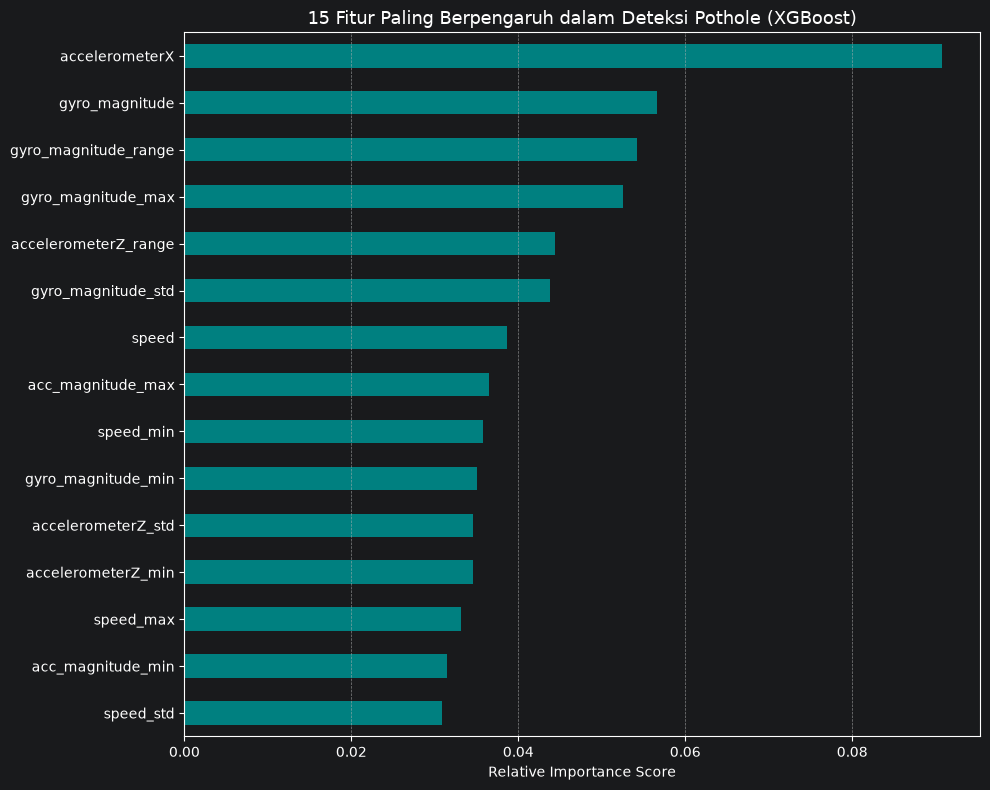

In [22]:
# Ambil model XGBoost dan nama fitur
xgb_step = best_model.named_steps["xgb"]
feature_names = X_train.columns

# Buat DataFrame Feature Importance
importances = pd.Series(xgb_step.feature_importances_, index=feature_names)
importances = importances.sort_values(ascending=True)

# Plot 15 Fitur Teratas
plt.figure(figsize=(10, 8))
importances.tail(15).plot(kind="barh", color="teal")
plt.title(
    "15 Fitur Paling Berpengaruh dalam Deteksi Pothole (XGBoost)", fontsize=13
)
plt.xlabel("Relative Importance Score")
plt.grid(axis="x", linestyle="--", alpha=0.7)
plt.tight_layout()
plt.show()

### Model XGBoost

In [23]:
best_params = search.best_params_
clean_params = {
    k.replace("xgb__", ""): v
    for k, v in best_params.items()
    if k.startswith("xgb__")
}

In [24]:
final_pipeline = Pipeline(
    [
        ("scaler", RobustScaler()),
        (
            "xgb",
            XGBClassifier(
                **clean_params,
                random_state=42,
                eval_metric="logloss",
                scale_pos_weight=ratio_imbalance,  # Penanganan Imbalanced Data
            ),
        ),
    ]
)

In [25]:
final_pipeline.fit(X_train, y_train)

,"steps steps: list of tuplesList of (name of step, estimator) tuples that are to be chained insequential order. To be compatible with the scikit-learn API, all stepsmust define `fit`. All non-last steps must also define `transform`. See:ref:`Combining Estimators <combining_estimators>` for more details.","[('scaler', ...), ('xgb', ...)]"
,"transform_input transform_input: list of str, default=NoneThe names of the :term:`metadata` parameters that should be transformed by thepipeline before passing it to the step consuming it.This enables transforming some input arguments to ``fit`` (other than ``X``)to be transformed by the steps of the pipeline up to the step which requiresthem. Requirement is defined via :ref:`metadata routing <metadata_routing>`.For instance, this can be used to pass a validation set through the pipeline.You can only set this if metadata routing is enabled, which youcan enable using ``sklearn.set_config(enable_metadata_routing=True)``... versionadded:: 1.6",None
,"memory memory: str or object with the joblib.Memory interface, default=NoneUsed to cache the fitted transformers of the pipeline. The last stepwill never be cached, even if it is a transformer. By default, nocaching is performed. If a string is given, it is the path to thecaching directory. Enabling caching triggers a clone of the transformersbefore fitting. Therefore, the transformer instance given to thepipeline cannot be inspected directly. Use the attribute ``named_steps``or ``steps`` to inspect estimators within the pipeline. Caching thetransformers is advantageous when fitting is time consuming. See:ref:`sphx_glr_auto_examples_neighbors_plot_caching_nearest_neighbors.py`for an example on how to enable caching.",None
,"verbose verbose: bool, default=FalseIf True, the time elapsed while fitting each step will be printed as itis completed.",False
Name,Type,Value
"classes_ classes_: ndarray of shape (n_classes,)The classes labels. Only exist if the last step of the pipeline is aclassifier.","ndarray[int64](2,)","[0,1]"
"feature_names_in_ feature_names_in_: ndarray of shape (`n_features_in_`,)Names of features seen during :term:`fit`. Only defined if theunderlying estimator exposes such an attribute when fit... versionadded:: 1.0","ndarray[object](32,)","['speed','accelerometerX','accelerometerY',...,'accelerometerZ_max', 'accelerometerZ_min','accelerometerZ_range']"
n_features_in_ n_features_in_: intNumber of features seen during :term:`fit`. Only defined if theunderlying first estimator in `steps` exposes such an attributewhen fit... versionadded:: 0.24,int,32
,"with_centering with_centering: bool, default=TrueIf `True`, center the data before scaling.This will cause :meth:`transform` to raise an exception when attemptedon sparse matrices, because centering them entails building a densematrix which in common use cases is likely to be too large to fit inmemory.",True
,"with_scaling with_scaling: bool, default=TrueIf `True`, scale the data to interquartile range.",True
,"quantile_range quantile_range: tuple (q_min, q_max), 0.0 < q_min < q_max < 100.0, default=(25.0, 75.0)Quantile range used to calculate `scale_`. By default this is equal tothe IQR, i.e., `q_min` is the first quantile and `q_max` is the thirdquantile... versionadded:: 0.18","(25.0, ...)"


### Classication Report

In [26]:
y_pred = final_pipeline.predict(X_test)
y_proba = final_pipeline.predict_proba(X_test)[:, 1]

# 2. Cetak Classification Report
print("=== CLASSIFICATION REPORT (DATA TEST) ===")
print(classification_report(y_test, y_pred, target_names=["Normal", "Pothole"]))

# 3. Hitung ROC-AUC Score
roc_score = roc_auc_score(y_test, y_proba)
print(f"ROC-AUC Score: {roc_score:.4f}")

=== CLASSIFICATION REPORT (DATA TEST) ===
              precision    recall  f1-score   support

      Normal       0.96      0.95      0.95      2266
     Pothole       0.94      0.95      0.95      1970

    accuracy                           0.95      4236
   macro avg       0.95      0.95      0.95      4236
weighted avg       0.95      0.95      0.95      4236

ROC-AUC Score: 0.9898


### Confusion Matrix

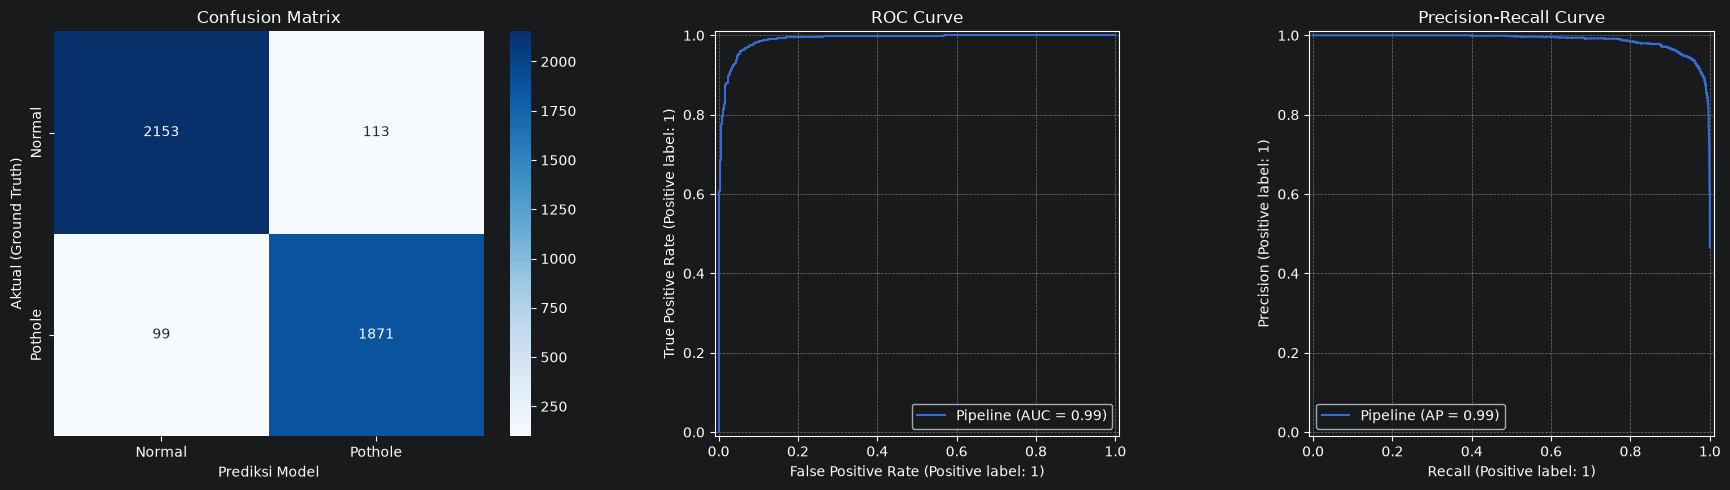

In [27]:

fig, axes = plt.subplots(1, 3, figsize=(18, 5))

cm = confusion_matrix(y_test, y_pred)
sns.heatmap(
    cm,
    annot=True,
    fmt="d",
    cmap="Blues",
    ax=axes[0],
    xticklabels=["Normal", "Pothole"],
    yticklabels=["Normal", "Pothole"],
)
axes[0].set_title("Confusion Matrix")
axes[0].set_xlabel("Prediksi Model")
axes[0].set_ylabel("Aktual (Ground Truth)")

# 2. Plot ROC Curve
RocCurveDisplay.from_estimator(final_pipeline, X_test, y_test, ax=axes[1])
axes[1].set_title("ROC Curve")
axes[1].grid(True, linestyle="--", alpha=0.6)

# 3. Plot Precision-Recall Curve (Krusial untuk Imbalanced Class)
PrecisionRecallDisplay.from_estimator(
    final_pipeline, X_test, y_test, ax=axes[2]
)
axes[2].set_title("Precision-Recall Curve")
axes[2].grid(True, linestyle="--", alpha=0.6)

plt.tight_layout()
plt.show()

### Fitur paling dominan

/var/folders/wr/yfr7rfvd10xbt_gpwcv9_ryh0000gn/T/ipykernel_7881/1659436603.py:11: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(


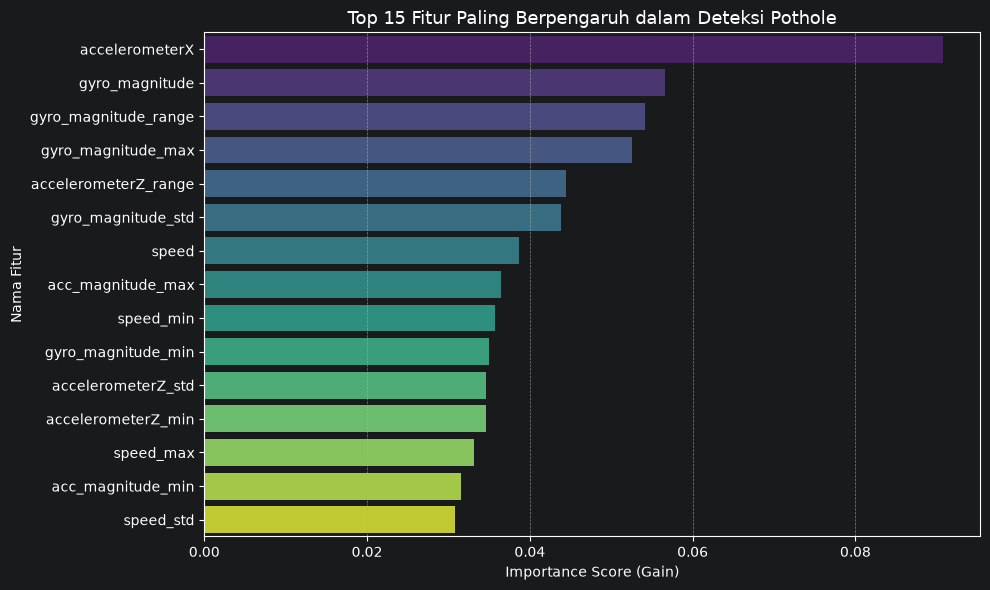

,Feature,Importance
0,accelerometerX,0.090767
1,gyro_magnitude,0.056566
2,gyro_magnitude_range,0.054194
3,gyro_magnitude_max,0.052548
4,accelerometerZ_range,0.044406
5,gyro_magnitude_std,0.043783
6,speed,0.038690
7,acc_magnitude_max,0.036510
8,speed_min,0.035721
9,gyro_magnitude_min,0.034995


In [28]:
# Ambil estimator XGBoost dari Pipeline
xgb_model = final_pipeline.named_steps["xgb"]

# Ambil Feature Importance (berdasarkan Gain)
importance_df = pd.DataFrame(
    {"Feature": X_train.columns, "Importance": xgb_model.feature_importances_}
).sort_values(by="Importance", ascending=False)

# Visualisasi Top 15 Fitur Teratas
plt.figure(figsize=(10, 6))
sns.barplot(
    data=importance_df.head(15), x="Importance", y="Feature", palette="viridis"
)
plt.title("Top 15 Fitur Paling Berpengaruh dalam Deteksi Pothole", fontsize=13)
plt.xlabel("Importance Score (Gain)")
plt.ylabel("Nama Fitur")
plt.grid(axis="x", linestyle="--", alpha=0.7)
plt.tight_layout()
plt.show()

# Display 10 Fitur Teratas dalam bentuk tabel
importance_df.head(10).reset_index(drop=True)

### Test menggunakan `y_test`

In [29]:
# Buat DataFrame Hasil Prediksi + Metadata GPS
df_test_results = meta_test.copy()
df_test_results["actual_label"] = y_test.values
df_test_results["predicted_label"] = y_pred
df_test_results["pothole_probability"] = y_proba

# Filter khusus untuk data yang diprediksi sebagai Pothole (Label = 1)
potholes_detected = df_test_results[df_test_results["predicted_label"] == 1]

print(f"Total Sampel Test          : {len(df_test_results)}")
print(f"Total Pothole Terdeteksi   : {len(potholes_detected)} titik lokasi")

# Tampilkan 5 sampel data terdeteksi pothole beserta koordinat GPS-nya
potholes_detected

Total Sampel Test          : 4236
Total Pothole Terdeteksi   : 1984 titik lokasi


,timestamp,latitude,longitude,actual_label,predicted_label,pothole_probability
3033,1.493003e+09,40.447591,-79.947533,1,1,0.999686
3201,1.493003e+09,40.445296,-79.948616,1,1,0.870954
637,1.492639e+09,40.453096,-79.947925,1,1,0.945206
9728,1.493003e+09,40.447096,-79.947001,1,1,0.895000
2368,1.493003e+09,40.450284,-79.944952,1,1,0.953385
...,...,...,...,...,...,...
6319,1.493004e+09,40.453323,-79.947171,1,1,0.999722
6855,1.493004e+09,40.447351,-79.947426,1,1,0.997566
615,1.492639e+09,40.453226,-79.947481,1,1,0.629915
8075,1.493002e+09,40.453547,-79.946479,1,1,0.983208


### Test dengan folium

In [30]:
# 1. Filter hasil prediksi data test yang terdeteksi sebagai Pothole (True Positive & False Positive)
pothole_locations = df_test_results[df_test_results["predicted_label"] == 1]

# 2. Tentukan titik tengah peta berdasarkan rerata GPS
center_lat = pothole_locations["latitude"].mean()
center_lon = pothole_locations["longitude"].mean()

# 3. Inisialisasi Peta Folium
m = folium.Map(location=[center_lat, center_lon], zoom_start=13)
marker_cluster = MarkerCluster().add_to(m)

# 4. Tambahkan Marker untuk setiap titik Pothole terdeteksi
for idx, row in pothole_locations.iterrows():
    # Menandai warna: Hijau untuk True Positive (Akurat), Merah untuk False Positive (Alarm Palsu)
    is_correct = row["actual_label"] == row["predicted_label"]
    color = "green" if is_correct else "red"
    status = (
        "Pothole Akurat" if is_correct else "Alarm Palsu (Potensi Jalan Rusak)"
    )

    popup_text = f"""
    <b>Status:</b> {status}<br>
    <b>Probabilitas:</b> {row['pothole_probability']:.2%}<br>
    <b>Lat:</b> {row['latitude']:.5f}<br>
    <b>Lon:</b> {row['longitude']:.5f}
    """

    folium.CircleMarker(
        location=[row["latitude"], row["longitude"]],
        radius=5,
        color=color,
        fill=True,
        fill_color=color,
        fill_opacity=0.7,
        popup=popup_text,
    ).add_to(marker_cluster)


print(
    "Peta interaktif berhasil disimpan sebagai 'pothole_detection_map.html'!"
)
m

Peta interaktif berhasil disimpan sebagai 'pothole_detection_map.html'!


In [34]:
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score

# =========================
# PREDICTION
# =========================
y_train_pred = final_pipeline.predict(X_train)
y_test_pred = final_pipeline.predict(X_test)


# =========================
# FUNCTION EVALUASI
# =========================
def evaluate_model(y_true, y_pred, name):
    return {
        "Dataset": name,
        "Accuracy": accuracy_score(y_true, y_pred),
        "Precision": precision_score(y_true, y_pred),
        "Recall": recall_score(y_true, y_pred),
        "F1 Score": f1_score(y_true, y_pred),
    }


# =========================
# HASIL
# =========================
results = pd.DataFrame([
    evaluate_model(y_train, y_train_pred, "Train"),
    evaluate_model(y_test, y_test_pred, "Test"),
])

print(results)

  Dataset  Accuracy  Precision    Recall  F1 Score
0   Train  0.999764   0.999873  0.999619  0.999746
1    Test  0.949953   0.943044  0.949746  0.946383


In [35]:
metrics = ["Accuracy", "Precision", "Recall", "F1 Score"]

for metric in metrics:
    train_score = results.loc[
        results["Dataset"] == "Train", metric
    ].iloc[0]

    test_score = results.loc[
        results["Dataset"] == "Test", metric
    ].iloc[0]

    gap = train_score - test_score

    print(f"{metric}:")
    print(f"  Train = {train_score:.4f}")
    print(f"  Test  = {test_score:.4f}")
    print(f"  Gap   = {gap:.4f}\n")

Accuracy:
  Train = 0.9998
  Test  = 0.9500
  Gap   = 0.0498

Precision:
  Train = 0.9999
  Test  = 0.9430
  Gap   = 0.0568

Recall:
  Train = 0.9996
  Test  = 0.9497
  Gap   = 0.0499

F1 Score:
  Train = 0.9997
  Test  = 0.9464
  Gap   = 0.0534



In [36]:
cv_results = pd.DataFrame(search.cv_results_)

best_idx = search.best_index_

for i in range(5):
    score = cv_results.loc[
        best_idx,
        f"split{i}_test_score"
    ]

    print(f"Fold {i + 1}: {score:.4f}")

Fold 1: 0.8196
Fold 2: 0.8671
Fold 3: 0.9103
Fold 4: 0.9203
Fold 5: 0.9273


In [37]:
scores = []

for i in range(5):
    scores.append(
        cv_results.loc[
            best_idx,
            f"split{i}_test_score"
        ]
    )

print("CV Scores:", scores)
print(f"Mean : {np.mean(scores):.4f}")
print(f"Std  : {np.std(scores):.4f}")

CV Scores: [np.float64(0.8195956454121306), np.float64(0.8671109368874951), np.float64(0.9103448275862069), np.float64(0.9202733485193622), np.float64(0.9272997032640949)]
Mean : 0.8889
Std  : 0.0405


In [31]:
# 1. Register XGBoost ke skl2onnx
update_registered_converter(
    XGBClassifier,
    "XGBoostXGBClassifier",
    calculate_linear_classifier_output_shapes,
    convert_xgboost,
    options={"nocl": [True, False], "zipmap": [True, False]},
)

# 2. Spesifikasi tipe data input (32 fitur float32)
num_features = X_train.shape[1]
initial_type = [("float_input", FloatTensorType([None, num_features]))]

# 3. Konversi Pipeline dengan target_opset dictionary (FIX ERROR)
onnx_model = convert_sklearn(
    final_pipeline,
    initial_types=initial_type,
    target_opset={
        "": 12,
        "ai.onnx.ml": 3,
    },  # <--- PERBAIKAN: Kunci ai.onnx.ml ke versi 3
    options={"zipmap": False},
)

# 4. Simpan model ONNX ke file
onnx_filename = "./models/hg_model_v1.onnx"
with open(onnx_filename, "wb") as f:
    f.write(onnx_model.SerializeToString())

print(f"Model Pipeline berhasil dikonversi ke '{onnx_filename}' (Opset ML v3)!")

Model Pipeline berhasil dikonversi ke './models/hg_model_v1.onnx' (Opset ML v3)!


In [33]:
# 1. Buat Inference Session ONNX
session = rt.InferenceSession("./models/hg_model_v1.onnx")
input_name = session.get_inputs()[0].name
label_name = session.get_outputs()[0].name
prob_name = session.get_outputs()[1].name

# 2. Uji dengan 5 data dari X_test (harus bertipe float32)
dummy_input = X_test.iloc[:5].values.astype(np.float32)

# 3. Jalankan Prediksi ONNX
onnx_pred, onnx_probs = session.run([label_name, prob_name], {input_name: dummy_input})

# 4. Bandingkan dengan model Python original
py_pred = final_pipeline.predict(X_test.iloc[:5])

print("=== VERIFIKASI AKURASI KONVERSI ===")
print("Prediksi Python Original :", py_pred)
print("Prediksi ONNX Runtime   :", onnx_pred)

# Uji apakah output identik
if np.array_equal(py_pred, onnx_pred):
    print("\n HASIL IDENTIK! Model ONNX 100% Valid dan Siap Deploy.")
else:
    print("\n Terdapat perbedaan hasil antara ONNX dan Python!")

=== VERIFIKASI AKURASI KONVERSI ===
Prediksi Python Original : [1 0 1 1 0]
Prediksi ONNX Runtime   : [1 0 1 1 0]

 HASIL IDENTIK! Model ONNX 100% Valid dan Siap Deploy.
